# Delta Air Lines: Flight Delay Prediction

**Applied Machine Learning - Fall 2026**

**Business question:** How can Delta Air Lines use historical flight information to anticipate arrival delays and support proactive operational decision-making?

**Machine learning question:** Using only information available before scheduled departure, how accurately can we predict whether a Delta-operated flight will arrive at least 15 minutes late, and which pre-departure flight characteristics are most predictive of delay risk?

**Scope:** U.S. BTS Reporting Carrier On-Time Performance records for 2025. We predict `ARR_DEL15` for completed flights with observed arrival outcomes. 

**Prediction timing:** Before scheduled departure. Actual departure/arrival outcomes must never be predictors.

This notebook documents the data processing and modelling workflow. All findings should be based on the actual output generated below.


#LAD OS KIGGE PÅ DENNE START IGEN INDEN VI AFLEVERER, HVIS DER SKAL TILFØJES NOGET ELLER MANGLER NOGET

## 1. Import libraries and configure paths

Here we run Jupyter from the repository root, where `flight_delay_analysis.ipynb` and `data/` are next to each other.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path("data")
MONTHLY_FILES = [DATA_DIR / f"{month:02d}-2025.csv" for month in range(1, 13)]

missing_files = [str(path) for path in MONTHLY_FILES if not path.is_file()]
if missing_files:
    raise FileNotFoundError(f"Missing BTS monthly file(s): {missing_files}")

print(f"Found all {len(MONTHLY_FILES)} monthly files.")

Found all 12 monthly files.


## 2. Data collection

We downloaded the 2025 flight data from BTS as twelve monthly files and stacked them on top of each other into one dataset. While loading each file, we check that all the columns we need are there, and that the file only contains flights from the right month. To keep the dataset small, we only keep flights operated by Delta (DL). We also save how many flights each month had in total and how many were Delta, so we can document how the dataset was built.

This is described in Section 2.1 of the report.

In [17]:
# the 11 columns we need, grouped in 4 categories
EXPECTED_COLUMNS = [
    # Flight Information
    "FL_DATE", "OP_UNIQUE_CARRIER", "ORIGIN", "DEST",
    # Schedule
    "CRS_DEP_TIME", "CRS_ARR_TIME", "CRS_ELAPSED_TIME", "DISTANCE",
    # Flight Status
    "CANCELLED", "DIVERTED",
    # Outcome (target)
    "ARR_DEL15",
]

# an empty list where we save the Delta flights from each month
monthly_delta = []

# going through the 12 monthly files one by one
for file_path in MONTHLY_FILES:
    # reading only the 11 columns we need
    monthly = pd.read_csv(file_path, usecols=EXPECTED_COLUMNS)

    # keeping only flights operated by Delta (DL)
    delta = monthly[monthly["OP_UNIQUE_CARRIER"] == "DL"]

    # showing how many flights the file had, and how many were Delta
    print(file_path.name, "- all flights:", len(monthly), "- Delta flights:", len(delta))

    # saving the Delta flights in the list
    monthly_delta.append(delta)

# stacking the 12 months on top of each other into one table
df = pd.concat(monthly_delta, ignore_index=True)

# turn FL_DATE from text into a real date, so we can get the month and weekday later
df["FL_DATE"] = pd.to_datetime(df["FL_DATE"], format="%m/%d/%Y %I:%M:%S %p")

# show the total number of Delta flights in 2025
print("Total Delta flights in 2025:", len(df))

# check that we have flights from all 12 months (1 = January, 12 = December)
df["FL_DATE"].dt.month.value_counts().sort_index()

01-2025.csv - all flights: 539747 - Delta flights: 76306
02-2025.csv - all flights: 504884 - Delta flights: 71333
03-2025.csv - all flights: 600872 - Delta flights: 84487
04-2025.csv - all flights: 583950 - Delta flights: 84188
05-2025.csv - all flights: 605648 - Delta flights: 89931
06-2025.csv - all flights: 611575 - Delta flights: 91122
07-2025.csv - all flights: 631428 - Delta flights: 94066
08-2025.csv - all flights: 602378 - Delta flights: 90313
09-2025.csv - all flights: 562439 - Delta flights: 84875
10-2025.csv - all flights: 605844 - Delta flights: 90097
11-2025.csv - all flights: 570550 - Delta flights: 84475
12-2025.csv - all flights: 582304 - Delta flights: 85139
Total Delta flights in 2025: 1026332


FL_DATE
1     76306
2     71333
3     84487
4     84188
5     89931
6     91122
7     94066
8     90313
9     84875
10    90097
11    84475
12    85139
Name: count, dtype: int64

## 3. Getting to know the data (EDA) & data quality

**The main idea (from Session 2):** before we clean the data, we first find the problems. In this section we only **look** at the data. We do not change anything yet.

**The plan:**
1. EDA – How big is the data, and what type of data is in each column?
2. Check 1 – Does each column look normal on its own?
3. Check 2 – Do the columns make sense together?
4. Check 3 – Does the data follow the rules?
5. Check 4 – What is missing, and why?
6. Summary – the 7 data quality dimensions

 **Step 1**

In [21]:
# ===== EDA: size and data types =====
# show the first 5 rows, to check that the data was read in correctly
display(df.head(5))

# number of rows (flights) and columns
print("--- Size ---")
print("Rows (flights):", df.shape[0])
print("Columns:", df.shape[1])

# first and last date, number of different dates and airports
print("\n--- Dates and airports ---")
print("Date range:", df["FL_DATE"].min().date(), "to", df["FL_DATE"].max().date())
print("Unique dates:", df["FL_DATE"].nunique())
print("Unique origin airports:", df["ORIGIN"].nunique())
print("Unique destination airports:", df["DEST"].nunique())

# column names, how many cells are filled in, and the data type of each column
print("\n--- Data types ---")
df.info()

,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,CRS_ARR_TIME,ARR_DEL15,CANCELLED,DIVERTED,CRS_ELAPSED_TIME,DISTANCE
0,2025-01-01,DL,ABQ,ATL,635,1132,0.0,0.0,0.0,177.0,1269.0
1,2025-01-01,DL,ABQ,ATL,1135,1633,0.0,0.0,0.0,178.0,1269.0
2,2025-01-01,DL,ABQ,MSP,800,1139,0.0,0.0,0.0,159.0,981.0
3,2025-01-01,DL,ALB,ATL,605,859,0.0,0.0,0.0,174.0,853.0
4,2025-01-01,DL,ALB,ATL,1413,1705,0.0,0.0,0.0,172.0,853.0


--- Size ---
Rows (flights): 1026332
Columns: 11

--- Dates and airports ---
Date range: 2025-01-01 to 2025-12-31
Unique dates: 365
Unique origin airports: 153
Unique destination airports: 153

--- Data types ---
<class 'pandas.DataFrame'>
RangeIndex: 1026332 entries, 0 to 1026331
Data columns (total 11 columns):
 #   Column             Non-Null Count    Dtype         
---  ------             --------------    -----         
 0   FL_DATE            1026332 non-null  datetime64[us]
 1   OP_UNIQUE_CARRIER  1026332 non-null  str           
 2   ORIGIN             1026332 non-null  str           
 3   DEST               1026332 non-null  str           
 4   CRS_DEP_TIME       1026332 non-null  int64         
 5   CRS_ARR_TIME       1026332 non-null  int64         
 6   ARR_DEL15          1012427 non-null  float64       
 7   CANCELLED          1026332 non-null  float64       
 8   DIVERTED           1026332 non-null  float64       
 9   CRS_ELAPSED_TIME   1026332 non-null  float64       
 

**Step 2 - Check 1: Does each column look normal on its own? (Univariate analysis)**

,DISTANCE,CRS_ELAPSED_TIME
count,1.026332e+06,1.026332e+06
mean,9.588129e+02,1.614236e+02
std,6.534858e+02,7.989110e+01
min,9.500000e+01,4.400000e+01
25%,4.810000e+02,1.010000e+02
50%,7.610000e+02,1.390000e+02
75%,1.276000e+03,2.020000e+02
max,5.095000e+03,7.390000e+02


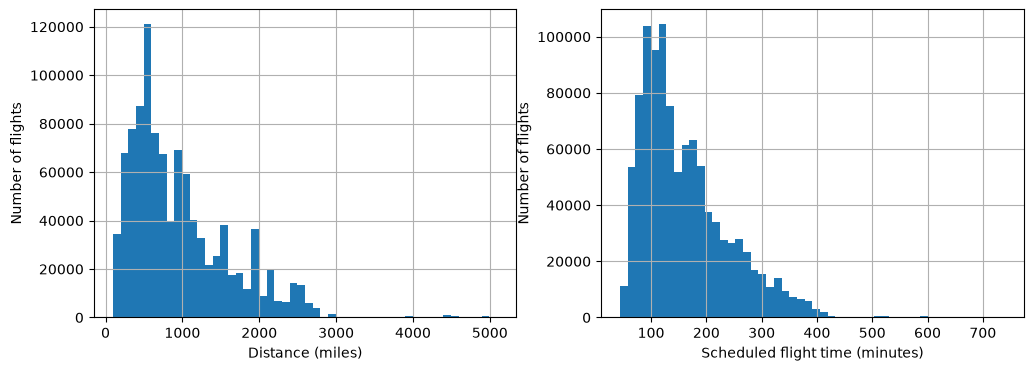

ARR_DEL15
0.0    0.802
1.0    0.198
Name: proportion, dtype: float64
Departure times between 1550 and 1610: [1550, 1551, 1552, 1553, 1554, 1555, 1556, 1557, 1558, 1559, 1600, 1601, 1602, 1603, 1604, 1605, 1606, 1607, 1608, 1609, 1610]
1600 - 1559 = 41


In [38]:
# smallest, largest and average value of the numbers we care about
display(df[["DISTANCE", "CRS_ELAPSED_TIME"]].describe())

# histograms of distance and scheduled flight time, side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["DISTANCE"].hist(bins=50, ax=axes[0])
axes[0].set(xlabel="Distance (miles)", ylabel="Number of flights")
df["CRS_ELAPSED_TIME"].hist(bins=50, ax=axes[1])
axes[1].set(xlabel="Scheduled flight time (minutes)", ylabel="Number of flights")
plt.show()

# share of on-time (0) and late (1) flights (value_counts skips empty cells by itself)
print(df["ARR_DEL15"].value_counts(normalize=True).round(3))

# the times are hhmm numbers: show the departure times that exist between 15:50 and 16:10
# there is no 1560-1599, so the numbers jump from 1559 straight to 1600
times = pd.Series(sorted(df["CRS_DEP_TIME"].unique()))
print("Departure times between 1550 and 1610:", times[times.between(1550, 1610)].tolist())

# 15:59 -> 16:00 is 1 minute, but as numbers the difference is 41
print("1600 - 1559 =", 1600 - 1559)

**Findings - Step 2:**
- **All values look realistic.** Distance goes from 95 to 5,095 miles, and flight time from 44 to 739 minutes. No zeros or negative values.
- **Times:** CRS_DEP_TIME and CRS_ARR_TIME are stored as hhmm numbers (1430 = 14:30). The output above shows that the numbers jump from 1559 straight to 1600, so they look 41 apart, although only one minute has passed. This is not an error, but it is a problem for a model. We therefore create an hour column (0–23) in Section 4.
- **Target:** 80.2% of the flights are on time and **19.8% are late**. This is **unbalanced data**, so accuracy alone can trick us. We will also use precision, recall and F1.

**Step 3 - Check 2: Do the columns make sense together? (Bivariate and Multivariate analysis)**

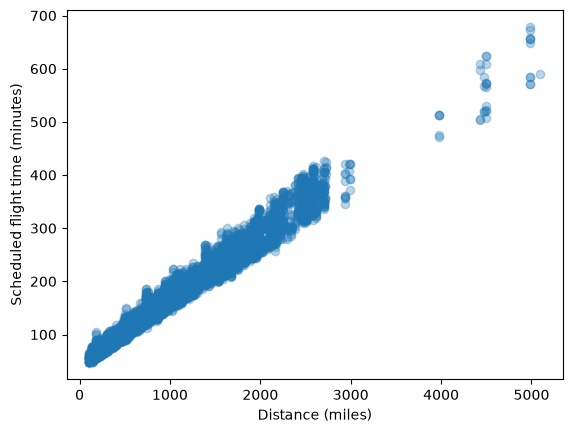

Correlation: 0.98
Strange flights: 0


In [35]:
# 10,000 random flights: distance vs. scheduled flight time
sample = df.sample(10000, random_state=1)
plt.scatter(sample["DISTANCE"], sample["CRS_ELAPSED_TIME"], alpha=0.3)
plt.xlabel("Distance (miles)")
plt.ylabel("Scheduled flight time (minutes)")
plt.show()

# correlation: 1 = perfect, 0 = no connection
print("Correlation:", round(df["DISTANCE"].corr(df["CRS_ELAPSED_TIME"]), 2))

# strange flights: over 1,500 miles but under 60 minutes (0 = none)
strange = df[(df["DISTANCE"] > 1500) & (df["CRS_ELAPSED_TIME"] < 60)]
print("Strange flights:", len(strange))

**Findings - Step 3:**
- Distance and flight time fit together: the longer the flight, the longer it takes (correlation 0.98).
- There are no strange flights, such as a long distance with a very short flight time.


**Step 4 - Check 3: Does the data follow the rules? (Constraint and rule checking)**

In [24]:
# True = all flights follow the rule, False = some flights break it
# % 100 gives the last two digits of the time (the minutes)
rules = {
    "ARR_DEL15 is only 0 or 1": df["ARR_DEL15"].dropna().isin([0, 1]).all(),
    "CANCELLED is only 0 or 1": df["CANCELLED"].isin([0, 1]).all(),
    "DIVERTED is only 0 or 1": df["DIVERTED"].isin([0, 1]).all(),
    "All flights are from 2025": (df["FL_DATE"].dt.year == 2025).all(),
    "CRS_DEP_TIME is 0-2359": df["CRS_DEP_TIME"].between(0, 2359).all(),
    "CRS_DEP_TIME minutes < 60": (df["CRS_DEP_TIME"] % 100 < 60).all(),
    "CRS_ARR_TIME is 0-2359": df["CRS_ARR_TIME"].between(0, 2359).all(),
    "CRS_ARR_TIME minutes < 60": (df["CRS_ARR_TIME"] % 100 < 60).all(),
    "DISTANCE is above 0": (df["DISTANCE"] > 0).all(),
    "CRS_ELAPSED_TIME is above 0": (df["CRS_ELAPSED_TIME"] > 0).all(),
    "ORIGIN and DEST are different": (df["ORIGIN"] != df["DEST"]).all(),
    "No duplicate rows": not df.duplicated().any(),
}

for rule, ok in rules.items():
    print(ok, "-", rule)

True - ARR_DEL15 is only 0 or 1
True - CANCELLED is only 0 or 1
True - DIVERTED is only 0 or 1
True - All flights are from 2025
True - CRS_DEP_TIME is 0-2359
True - CRS_DEP_TIME minutes < 60
True - CRS_ARR_TIME is 0-2359
True - CRS_ARR_TIME minutes < 60
True - DISTANCE is above 0
True - CRS_ELAPSED_TIME is above 0
True - ORIGIN and DEST are different
True - No duplicate rows


**Findings - Step 4 - Check 3:**
We made a list of rules that must always be true, for example:
- yes/no columns can only be 0 or 1
- times must be real clock times (00:00–23:59)
- distance and flight time must be above 0
- a flight can't land at the same airport it left from
- the same flight can't appear twice

All rules were **True**, so no flight breaks any rule. We found **no impossible values** in the data.

**Step 5 - Check 4: What is missing, and why? (Missingness analysis)**

In [25]:
# number of empty cells in each column
print(df.isna().sum())
print()

# are the flights with an empty target cancelled or diverted?
missing = df[df["ARR_DEL15"].isna()]
print("Flights with empty target:", len(missing))
print("Of these, cancelled:", int(missing["CANCELLED"].sum()))
print("Of these, diverted:", int(missing["DIVERTED"].sum()))

# share of flights with an empty target for each month (0.03 = 3%)
print()
print("Share of empty targets per month:")
print(df["ARR_DEL15"].isna().groupby(df["FL_DATE"].dt.month).mean().round(3))

FL_DATE                  0
OP_UNIQUE_CARRIER        0
ORIGIN                   0
DEST                     0
CRS_DEP_TIME             0
CRS_ARR_TIME             0
ARR_DEL15            13905
CANCELLED                0
DIVERTED                 0
CRS_ELAPSED_TIME         0
DISTANCE                 0
dtype: int64

Flights with empty target: 13905
Of these, cancelled: 11114
Of these, diverted: 2791

Share of empty targets per month:
FL_DATE
1     0.030
2     0.004
3     0.007
4     0.007
5     0.005
6     0.022
7     0.019
8     0.011
9     0.003
10    0.005
11    0.019
12    0.030
Name: ARR_DEL15, dtype: float64


**Findings - Step 5:**

**1. How much is missing?:** Only the target ARR_DEL15: 13,905 flights.

**2. Who is missing?:** All of them are cancelled (11,114) or diverted (2,791) flights. They are most common in January and December (3%) and rare in February and September (under 0.5%).

**3. Which type is it?:** = **MAR.** There is a clear pattern, and we can see the reason in other columns (CANCELLED, DIVERTED and the month). It is not MCAR (not random) and not MNAR (the reason is not hidden).

**4. What do we do?:** We **remove** these flights in the next section **(SECTION 4)**. The reason for removing them is due to for example filling in the average (about 0.2) makes no sense, because a flight can't be "0.2 late", and a cancelled flight never arrived.

**5. How could it affect our results?:** Cancellations are most common in busy winter and holiday months. Removing them may make the data look slightly calmer than reality, and the model cannot predict cancellations.

**Summary – the 7 data quality dimensions**

| Dimension | What it asks | Our answer |
|---|---|---|
| Accuracy | Are the values correct? | Yes. The data comes from BTS, and all values look realistic (Check 1). |
| Completeness | Is anything missing? | Only the target, for 1.4% of the flights (Check 4). |
| Consistency | Is everything written the same way? | Yes. For example, all times are written as hhmm (Check 1). |
| Timeliness | Is the data recent enough? | Yes. 2025 is the newest full year. |
| Validity | Does the data follow the rules? | Yes. All rules are True, and there are no duplicates (Check 3). |
| Relevance | Does the data fit our question? | Yes. We only use information known before the flight, plus the target. |
| Representativeness | Does the data show the full picture? | Mostly. We have all Delta flights in 2025, but removing cancelled and diverted flights leaves out some of the worst days. |

**Conclusion:** The data is in good shape. We found two things to handle in Section 4: the missing target for cancelled and diverted flights, and the hhmm format of the scheduled times, which we turn into hours.

## 4. Data wrangling 

**The plan**
1. Remove the flights without a target
2. Create new features from the date and the times
2. Check the data again

**Note on the date:** FL_DATE was already turned into a real date in SECTION 2, when we loaded the data. We did it there because the checks in SECTION 3 needed to read the date, for example to check that all flights are from 2025. This does not change any values, it only changes the format, so pandas can read the text as a date.

**Step 1: Remove the flights without a target**

In [26]:
# keep only flights that have a target (not cancelled and not diverted)
clean = df[df["ARR_DEL15"].notna()].copy()

# the target is now only 0 or 1, so we store it as a whole number
clean["ARR_DEL15"] = clean["ARR_DEL15"].astype(int)

print("Before:", len(df), "flights")
print("After:", len(clean), "flights")
print("Removed:", len(df) - len(clean), "flights")

Before: 1026332 flights
After: 1012427 flights
Removed: 13905 flights


**Findings - Step 1:** We removed 13,905 flights. As shown in Check 4, the target is missing at random (MAR), because all of these flights were cancelled or diverted. They never arrived, so there is no delay to predict. We now have 1,012,427 flights.

**Step 2: Create new features**

In [33]:
# month (1 = January, 12 = December) and weekday (1 = Monday, 7 = Sunday) from the date
clean["MONTH"] = clean["FL_DATE"].dt.month
clean["DAY_OF_WEEK"] = clean["FL_DATE"].dt.dayofweek + 1

# hour of the scheduled departure and arrival: // 100 removes the minutes (1430 -> 14)
clean["DEP_HOUR"] = clean["CRS_DEP_TIME"] // 100
clean["ARR_HOUR"] = clean["CRS_ARR_TIME"] // 100

# show 5 flights, to check that the new columns look right
display(clean[["FL_DATE", "MONTH", "DAY_OF_WEEK", "CRS_DEP_TIME", "DEP_HOUR", "CRS_ARR_TIME", "ARR_HOUR"]].head())

,FL_DATE,MONTH,DAY_OF_WEEK,CRS_DEP_TIME,DEP_HOUR,CRS_ARR_TIME,ARR_HOUR
0,2025-01-01,1,3,635,6,1132,11
1,2025-01-01,1,3,1135,11,1633,16
2,2025-01-01,1,3,800,8,1139,11
3,2025-01-01,1,3,605,6,859,8
4,2025-01-01,1,3,1413,14,1705,17


**Findings - Step 2:** We made four new features. MONTH and DAY_OF_WEEK come from the date, so we can see seasonal and weekly patterns. DEP_HOUR and ARR_HOUR come from the scheduled times. The times are stored as hhmm numbers (see Check 1), where 1559 and 1600 look 41 apart although only one minute has passed. The hour gives an even scale from 0 to 23.

**Step 3: Check the data again**

In [32]:
# size, empty cells and the target after the changes
print("Rows and columns:", clean.shape)
print("Empty cells in total:", clean.isna().sum().sum())
print(clean["ARR_DEL15"].value_counts(normalize=True).round(3))

# check that the new columns only have possible values
print("MONTH is 1-12:", clean["MONTH"].between(1, 12).all())
print("DAY_OF_WEEK is 1-7:", clean["DAY_OF_WEEK"].between(1, 7).all())
print("DEP_HOUR is 0-23:", clean["DEP_HOUR"].between(0, 23).all())
print("ARR_HOUR is 0-23:", clean["ARR_HOUR"].between(0, 23).all())

# share of delayed flights for each departure hour (0.08 = 8%)
display(clean.groupby("DEP_HOUR")["ARR_DEL15"].mean().round(2).to_frame("delay_rate"))

Rows and columns: (1012427, 15)
Empty cells in total: 0
ARR_DEL15
0    0.802
1    0.198
Name: proportion, dtype: float64
MONTH is 1-12: True
DAY_OF_WEEK is 1-7: True
DEP_HOUR is 0-23: True
ARR_HOUR is 0-23: True


,delay_rate
DEP_HOUR,
0,0.14
1,0.17
3,0.25
5,0.08
6,0.09
7,0.12
8,0.13
9,0.15
10,0.16


**Findings - Step 3:**
- **Size:** We now have 1,012,427 flights and 15 columns: the 11 original columns plus the 4 new features.
- **No empty cells:** Removing the flights without a target worked, so no values are missing.
- **Target:** 80.2% of the flights are on time and 19.8% are delayed. This is the same as before, so removing the cancelled and diverted flights did not change the balance.
- **New features:** All four new columns only contain possible values (all True).
- **Delays by hour:** The share of delayed flights rises during the day, from 8% at 5 am to 31% at 7 pm, and then drops to 22% late in the evening. This shows that the departure hour is a useful feature. Hours 2 and 4 are missing because Delta has no departures at those times.

The airports (ORIGIN and DEST) are one-hot encoded later, after the train/test split, so that the encoder only learns from the training data.